In [221]:
pip install matplotlib


Note: you may need to restart the kernel to use updated packages.


In [222]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [223]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
#import sqlite3


In [224]:
# pip install pandas sqlalchemy psycopg2-binary
import pandas as pd
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

# ---------- 1. Connect to PostgreSQL ----------
url = URL.create(
    "postgresql+psycopg2",
    username="postgres",
    password="YOUR_PASSWORD",   # special characters like @ are safe here
    host="localhost",
    port=5432,
    database="customer_churn",
)
engine = create_engine(url)

# ---------- 2. Find all tables in the public schema ----------
tables = pd.read_sql(
    "SELECT table_name FROM information_schema.tables "
    "WHERE table_schema = 'public' AND table_type = 'BASE TABLE' "
    "ORDER BY table_name",
    engine,
)

# ---------- 3. Load every table into its own DataFrame ----------
dataframes = {}
for table_name in tables["table_name"]:
    df = pd.read_sql(f'SELECT * FROM public."{table_name}"', engine)
    dataframes[table_name] = df                  # dataframes["table_name"]
    globals()[f"df_{table_name}"] = df           # df_table_name
    print(f"created dataframe: df_{table_name}  ->  {df.shape[0]} rows, {df.shape[1]} columns")

# ---------- 4. Use the DataFrames directly ----------
df_customers = dataframes["customer_churn_data_raw"]
df_complaints = dataframes["customer_complaints_raw"]
df_subscriptions = dataframes["customer_subscriptions_raw"]

# ---------- 5. Quick check ----------
print(df_customers.head(10))
print(df_complaints.head(10))
print(df_subscriptions.head(10))



created dataframe: df_customer_churn_data_raw  ->  21 rows, 8 columns
created dataframe: df_customer_complaints_raw  ->  9 rows, 6 columns
created dataframe: df_customer_subscriptions_raw  ->  21 rows, 11 columns
   customerid    name country        state  gender         dob interests  \
0  0002-ORFBO  keshav   India  Maharashtra    Male  12-04-1982    travel   
1  0003-MKNFE  raghav   India    Karnataka    Male  23-11-1995       NaN   
2  0004-TLHLJ  lalita   India        Delhi  Female  15-02-1978     movie   
3  0011-IGKFF   mohan   India     Nagaland    Male  30-08-2001       NaN   
4  0013-EXCHZ    mira   India        Delhi  Female  05-05-1990     drama   
5  0013-MHZWF   durga     NaN        Delhi   Women  10-12-1988       NaN   
6  0013-SMEOE    mina   India    Meghalaya  Female  21-09-1976       NaN   
7  0014-BMAQU   madan   India    Rajasthan    Male  14-03-1999       NaN   
8  0015-UOCOJ    maya     NaN    Kathmandu   Women  07-07-1985       NaN   
9  0016-QLJIS   arjun   Nep

In [225]:
df_customers.head(1)

,customerid,name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,12-04-1982,travel,None


In [226]:
#rename column: name
df_customers.rename(columns={'name':'customer_name'},inplace=True)

In [227]:
df_customers.head(1)

,customerid,customer_name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,12-04-1982,travel,None


In [228]:
# drop column intrests ,pincode
df_customers.drop(columns=['interests','pincode'],inplace=True)
df_customers.head(1)

,customerid,customer_name,country,state,gender,dob
0,0002-ORFBO,keshav,India,Maharashtra,Male,12-04-1982


In [229]:
df_customers.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   customerid     21 non-null     str  
 1   customer_name  21 non-null     str  
 2   country        18 non-null     str  
 3   state          21 non-null     str  
 4   gender         21 non-null     str  
 5   dob            21 non-null     str  
dtypes: str(6)
memory usage: 1.1 KB


In [230]:
# change data type: dob
df_customers['dob'] = pd.to_datetime(df_customers['dob'], format='%d-%m-%Y', errors='coerce')

df_customers.head(1)

,customerid,customer_name,country,state,gender,dob
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12


In [231]:
# change data type: dob

df_customers.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   customerid     21 non-null     str           
 1   customer_name  21 non-null     str           
 2   country        18 non-null     str           
 3   state          21 non-null     str           
 4   gender         21 non-null     str           
 5   dob            21 non-null     datetime64[us]
dtypes: datetime64[us](1), str(5)
memory usage: 1.1 KB


In [232]:
# data standarization -gender
#df_customers['gender'].unique()
#df_customers['gender'].replace({'Men':'Male','Women':'Female'},inplace=True)
df_customers['gender'] = df_customers['gender'].replace(
    {'Men': 'Male', 'Women': 'Female'}
)

In [233]:
df_customers['gender'].unique()

<StringArray>
['Male', 'Female']
Length: 2, dtype: str

In [234]:
#fixing missing value - country
df_customers['country'].isna()

0     False
1     False
2     False
3     False
4     False
5      True
6     False
7     False
8      True
9     False
10    False
11    False
12     True
13    False
14    False
15    False
16    False
17    False
18    False
19    False
20    False
Name: country, dtype: bool

In [235]:
df_customers[df_customers['country'].isna()]

,customerid,customer_name,country,state,gender,dob
5,0013-MHZWF,durga,NaN,Delhi,Female,1988-12-10
8,0015-UOCOJ,maya,NaN,Kathmandu,Female,1985-07-07
12,0018-NYROU,chitra,NaN,Telangana,Female,2004-12-01


In [236]:
df_customers[['country','state']]

,country,state
0,India,Maharashtra
1,India,Karnataka
2,India,Delhi
3,India,Nagaland
4,India,Delhi
5,NaN,Delhi
6,India,Meghalaya
7,India,Rajasthan
8,NaN,Kathmandu
9,Nepal,Kathmandu


In [237]:
state_country_mapping=df_customers.dropna(subset=['country']).set_index('state')['country'].to_dict()
df_customers['country']=df_customers['country'].fillna(df_customers['state'].map(state_country_mapping))


In [238]:
df_customers[['country','state']]

,country,state
0,India,Maharashtra
1,India,Karnataka
2,India,Delhi
3,India,Nagaland
4,India,Delhi
5,India,Delhi
6,India,Meghalaya
7,India,Rajasthan
8,Nepal,Kathmandu
9,Nepal,Kathmandu


In [239]:
df_subscriptions.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,None,NaN,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,None,NaN,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,None,NaN,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88


In [240]:
df_subscriptions.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               21 non-null     str    
 1   subscription_start_date  21 non-null     object 
 2   subscription_type        21 non-null     str    
 3   renewal_date             21 non-null     object 
 4   plan_type                21 non-null     str    
 5   contract_type            21 non-null     str    
 6   cancellation_date        6 non-null      object 
 7   cancellation_reason      6 non-null      str    
 8   monthly_charges          21 non-null     float64
 9   cltv                     21 non-null     int64  
 10  churn_score              21 non-null     int64  
dtypes: float64(1), int64(2), object(3), str(5)
memory usage: 1.9+ KB


In [241]:
list_datetime = ['subscription_start_date', 'renewal_date', 'cancellation_date']

df_subscriptions[list_datetime] = df_subscriptions[list_datetime].apply(pd.to_datetime)

In [242]:
df_subscriptions.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype        
---  ------                   --------------  -----        
 0   customerid               21 non-null     str          
 1   subscription_start_date  21 non-null     datetime64[s]
 2   subscription_type        21 non-null     str          
 3   renewal_date             21 non-null     datetime64[s]
 4   plan_type                21 non-null     str          
 5   contract_type            21 non-null     str          
 6   cancellation_date        6 non-null      datetime64[s]
 7   cancellation_reason      6 non-null      str          
 8   monthly_charges          21 non-null     float64      
 9   cltv                     21 non-null     int64        
 10  churn_score              21 non-null     int64        
dtypes: datetime64[s](3), float64(1), int64(2), str(5)
memory usage: 1.9 KB


In [243]:
df_complaints.head(10)

,customerid,complaint_date,escalations,csat_score,col_1,comment
0,0003-MKNFE,28-08-2024,N,60,None,service issue
1,0003-MKNFE,28-08-2024,Y,10,None,demaned refund
2,0013-EXCHZ,20-01-2024,Y,20,None,NaN
3,0013-MHZWF,18-03-2025,N,90,None,guidance to renew
4,0013-SMEOE,01-11-2024,N,30,None,NaN
5,0017-IUDMW,10-04-2024,Y,25,None,NaN
6,0019-EFAEP,27-09-2024,Y,30,None,NaN
7,0022-TCJCI,13-09-2024,Y,10,None,NaN
8,0022-TCJCI,14-09-2024,N,90,None,received refund


In [244]:
df_complaints.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   customerid      9 non-null      str   
 1   complaint_date  9 non-null      str   
 2   escalations     9 non-null      str   
 3   csat_score      9 non-null      int64 
 4   col_1           0 non-null      object
 5   comment         4 non-null      str   
dtypes: int64(1), object(1), str(4)
memory usage: 564.0+ bytes


In [245]:
df_complaints.drop(columns=['col_1','comment'],inplace=True)

In [246]:
df_complaints.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   customerid      9 non-null      str  
 1   complaint_date  9 non-null      str  
 2   escalations     9 non-null      str  
 3   csat_score      9 non-null      int64
dtypes: int64(1), str(3)
memory usage: 420.0 bytes


In [247]:
df_complaints['complaint_date']=pd.to_datetime(df_complaints['complaint_date'], format='%d-%m-%Y',errors='coerce')
#df_customers['dob'] = pd.to_datetime(df_customers['dob'], format='%d-%m-%Y', errors='coerce')


In [248]:
df_complaints.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customerid      9 non-null      str           
 1   complaint_date  9 non-null      datetime64[us]
 2   escalations     9 non-null      str           
 3   csat_score      9 non-null      int64         
dtypes: datetime64[us](1), int64(1), str(2)
memory usage: 420.0 bytes


In [249]:
#Feature engineering and data analysis

In [250]:
df_subscriptions.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88


In [251]:
df_subscriptions['churned_flag']=np.where(df_subscriptions['cancellation_date'].notna(),1,0)


In [252]:
#create an new column using existing column churned flag if customer has left the then 1, otherwise 0
df_subscriptions.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churned_flag
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,12,0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,34,0
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,8,0
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88,1


In [253]:
#first fix complaints table then merge
df = (
    df_subscriptions.merge(df_complaints, on='customerid', how='left').merge(df_customers, on='customerid', how='left')
)

In [254]:
df.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churned_flag,complaint_date,escalations,csat_score,customer_name,country,state,gender,dob
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,12,0,NaT,NaN,NaN,keshav,India,Maharashtra,Male,1982-04-12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1,2024-08-28,N,60.0,raghav,India,Karnataka,Male,1995-11-23
2,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1,2024-08-28,Y,10.0,raghav,India,Karnataka,Male,1995-11-23
3,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,34,0,NaT,NaN,NaN,lalita,India,Delhi,Female,1978-02-15
4,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,8,0,NaT,NaN,NaN,mohan,India,Nagaland,Male,2001-08-30


In [255]:
df_subscriptions.shape

(21, 12)

In [256]:
df.shape

(23, 20)

In [257]:
df_subscriptions['customerid'].nunique()


21

In [258]:
df_complaints['customerid'].nunique()

7

In [259]:
df_customers['customerid'].nunique()

21

In [260]:
df_complaints['customerid'].nunique()

7

In [261]:
# here is the mistake as we can see there are 9 rowa out of with two are not unique that way there are copy of data is created in merg table
df_complaints['customerid'].size

9

In [262]:
df_complaints.groupby('customerid')['customerid'].transform('count')

0    2
1    2
2    1
3    1
4    1
5    1
6    1
7    2
8    2
Name: customerid, dtype: int64

In [263]:
df_complaints['complaints_count']=df_complaints.groupby('customerid')['customerid'].transform('count')

In [264]:
df_complaints

,customerid,complaint_date,escalations,csat_score,complaints_count
0,0003-MKNFE,2024-08-28,N,60,2
1,0003-MKNFE,2024-08-28,Y,10,2
2,0013-EXCHZ,2024-01-20,Y,20,1
3,0013-MHZWF,2025-03-18,N,90,1
4,0013-SMEOE,2024-11-01,N,30,1
5,0017-IUDMW,2024-04-10,Y,25,1
6,0019-EFAEP,2024-09-27,Y,30,1
7,0022-TCJCI,2024-09-13,Y,10,2
8,0022-TCJCI,2024-09-14,N,90,2


In [265]:
df_complaints.sort_values('complaint_date').drop_duplicates('customerid',keep='last')

,customerid,complaint_date,escalations,csat_score,complaints_count
2,0013-EXCHZ,2024-01-20,Y,20,1
5,0017-IUDMW,2024-04-10,Y,25,1
1,0003-MKNFE,2024-08-28,Y,10,2
8,0022-TCJCI,2024-09-14,N,90,2
6,0019-EFAEP,2024-09-27,Y,30,1
4,0013-SMEOE,2024-11-01,N,30,1
3,0013-MHZWF,2025-03-18,N,90,1


In [266]:
df_complaints=df_complaints.sort_values('complaint_date').drop_duplicates('customerid',keep='last')

In [267]:
#first fix complaints table then merge
df = (
    df_subscriptions.merge(df_complaints, on='customerid', how='left').merge(df_customers, on='customerid', how='left')
)

In [268]:
df.shape

(21, 21)

In [269]:
#saved in dekstop
df.to_csv(
    r'C:\Users\HP\OneDrive\Desktop\exported_churn_data.csv',
    index=False
)

In [270]:
# DATA ANALYSIS

In [271]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churned_flag', 'complaint_date', 'escalations', 'csat_score',
       'complaints_count', 'customer_name', 'country', 'state', 'gender',
       'dob'],
      dtype='str')

In [272]:
#1 CHURN RATE
churn_rate=df['churned_flag'].mean()*100
print("churn rate=",round(churn_rate,2),"%")

churn rate= 28.57 %


In [273]:
#2 RETENTION RATE
retention_rate=100-churn_rate
print("retention rate",round(retention_rate,2),"%")

retention rate 71.43 %


In [274]:
#3 churn by Plan type
churn_by_plane=df.groupby('plan_type')['churned_flag'].mean().mul(100).round(2).reset_index(name='churn_rate_pct')
print(churn_by_plane)

  plan_type  churn_rate_pct
0     Basic           60.00
1   Premium           14.29
2  Standard           22.22


In [275]:
#4a. churn by state + sum(revenue) + count of user
#4b. churn by subscription type + sum(revenue) + count

In [276]:
df.groupby('state').agg(
    churn_rate=('churned_flag', 'mean'),
    total_monthly_charges=('monthly_charges', 'sum'),
    customer_count=('customerid', 'count')
).reset_index()

,state,churn_rate,total_monthly_charges,customer_count
0,Delhi,0.250000,52.96,4
1,Karnataka,1.000000,20.98,2
2,Kathmandu,0.000000,20.98,2
3,Maharashtra,0.000000,50.97,3
4,Meghalaya,0.666667,42.97,3
5,Nagaland,0.000000,22.99,1
6,Rajasthan,0.000000,36.98,2
7,Telangana,0.500000,30.98,2
8,Uttar Pradesh,0.000000,115.98,2


In [277]:
df.groupby('subscription_type').agg(
    churn_rate=('churned_flag', 'mean'),
    total_monthly_charges=('monthly_charges', 'sum'),
    customer_count=('customerid', 'count')
).reset_index()

,subscription_type,churn_rate,total_monthly_charges,customer_count
0,Organic,0.000000,145.91,9
1,Paid,0.166667,174.94,6
2,Refferal,0.833333,74.94,6


In [278]:
#5.ARPU avg revenue per use
arup=df['monthly_charges'].mean().round(2)
print("average revenue per user",arup)

average revenue per user 18.85


In [279]:
#6. average customer tenure
# count the days user have  used our servece : cancellation date current dateto
today=pd.Timestamp.today()
df['tenure_days']=np.where(
    df['cancellation_date'].notna(),(df['complaint_date']-df['subscription_start_date']).dt.days,
    (today - df['subscription_start_date']).dt.days
)
avg_tenure=df['tenure_days'].mean()

In [280]:
df


,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,complaint_date,escalations,csat_score,complaints_count,customer_name,country,state,gender,dob,tenure_days
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,...,NaT,NaN,NaN,NaN,keshav,India,Maharashtra,Male,1982-04-12,2045.0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,2024-08-28,Y,10.0,2.0,raghav,India,Karnataka,Male,1995-11-23,1488.0
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,...,NaT,NaN,NaN,NaN,lalita,India,Delhi,Female,1978-02-15,1430.0
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,...,NaT,NaN,NaN,NaN,mohan,India,Nagaland,Male,2001-08-30,2720.0
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,...,2024-01-20,Y,20.0,1.0,mira,India,Delhi,Female,1990-05-05,380.0
5,0013-MHZWF,2022-06-18,Paid,2025-06-18,Standard,Annual,NaT,NaN,17.99,720,...,2025-03-18,N,90.0,1.0,durga,India,Delhi,Female,1988-12-10,1585.0
6,0013-SMEOE,2021-09-30,Refferal,2024-09-30,Basic,Monthly,2024-11-15,Not enough content,8.99,230,...,2024-11-01,N,30.0,1.0,mina,India,Meghalaya,Female,1976-09-21,1128.0
7,0014-BMAQU,2020-02-14,Organic,2025-02-14,Premium,Annual,NaT,NaN,22.99,1840,...,NaT,NaN,NaN,NaN,madan,India,Rajasthan,Male,1999-03-14,2440.0
8,0015-UOCOJ,2023-07-22,Organic,2024-07-22,Standard,Monthly,NaT,NaN,13.99,240,...,NaT,NaN,NaN,NaN,maya,Nepal,Kathmandu,Female,1985-07-07,1186.0
9,0016-QLJIS,2022-04-03,Organic,2025-04-03,Basic,Annual,NaT,NaN,6.99,335,...,NaT,NaN,NaN,NaN,arjun,Nepal,Kathmandu,Male,1993-10-29,1661.0


In [281]:
#7. revenue lost from churned user
revenue_at_risk=df.loc[df['churned_flag']==1,'monthly_charges'].sum()
print("revenue at risk(rs k):",revenue_at_risk)

revenue at risk(rs k): 73.94


In [282]:
#Esclation Rate
esclation_rate=(df['escalations']=='Y').mean()*100
print("Esclation Rate = ",round(esclation_rate,2),"%")


Esclation Rate =  19.05 %


In [283]:
#9. Average complain rate
avg_complaints=df['complaints_count'].sum()/df['customerid'].nunique()
print("Average complain rate",round(avg_complaints,2))

Average complain rate 0.43


In [284]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churned_flag', 'complaint_date', 'escalations', 'csat_score',
       'complaints_count', 'customer_name', 'country', 'state', 'gender',
       'dob', 'tenure_days'],
      dtype='str')

In [285]:
df['complaints_count'].sum()

np.float64(9.0)

In [286]:
# 10 churn risk 
conditions=[
    (df['churn_score']<50),
    ((df['churn_score']>=50) & (df['churn_score']<70)),
    (df['churn_score']>=70)
]
choose=['low','mid','high']
df['churn_risk']=np.select(conditions,choose,default='unknown')
# Print churn score and its assigned risk category
print("Churn score and risk category:")
print(df[['churn_score', 'churn_risk']].head())

Churn score and risk category:
   churn_score churn_risk
0           12        low
1           91       high
2           34        low
3            8        low
4           88       high


In [287]:
# Visualization usin matplotbil

In [288]:
df_visual=df.copy()
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churned_flag', 'complaint_date', 'escalations', 'csat_score',
       'complaints_count', 'customer_name', 'country', 'state', 'gender',
       'dob', 'tenure_days', 'churn_risk'],
      dtype='str')

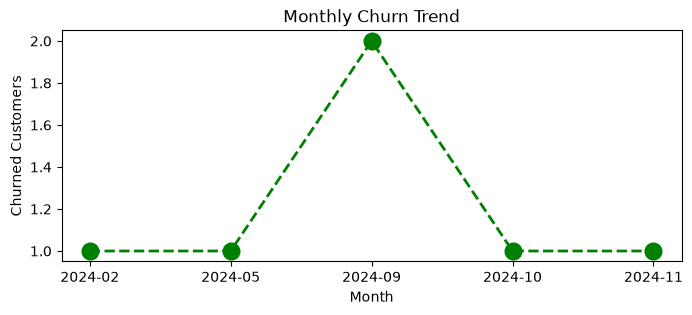

In [289]:
#4.1 Monthly churn trend (Time series KPI)
df_visual['cancellation_month'] = df_visual['cancellation_date'].dt.to_period('M')

churn_trend = df_visual[df_visual['churned_flag'] == 1].groupby('cancellation_month').size()

plt.figure(figsize=(8,3))
plt.plot(churn_trend.index.astype(str), churn_trend.values, color='green', marker='o', linestyle='dashed', linewidth=2, markersize=12)

plt.title('Monthly Churn Trend')
plt.xlabel('Month')
plt.ylabel('Churned Customers')
plt.show()

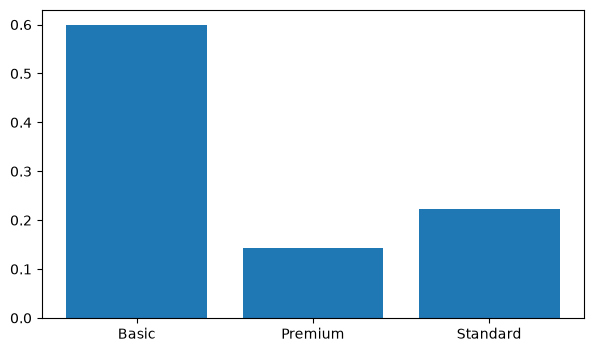

In [290]:
# 4.2 Churn by Plan type
churn_plan = df_visual.groupby('plan_type')['churned_flag'].mean()
plt.figure(figsize=(7,4))

plt.bar(churn_plan.index, churn_plan.values)
plt.show()

<Axes: >

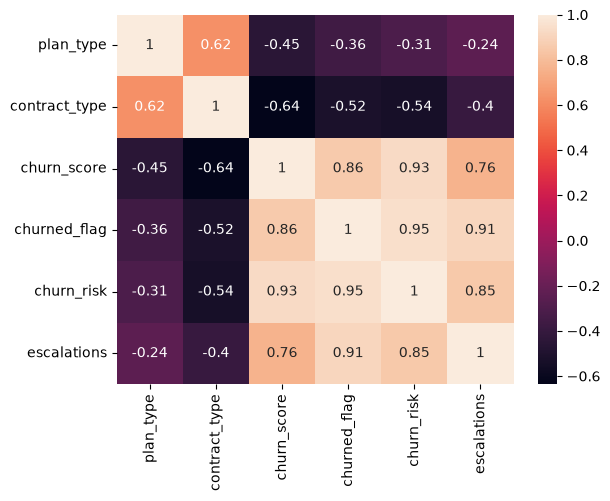

In [297]:
# Correct method of encoding based on priority

df_encoded = df_visual[
    [
        'plan_type',
        'contract_type',
        'churn_score',
        'churned_flag',
        'churn_risk',
        'escalations'
    ]
].copy()
# Define the order for categorical columns
order_mappings = {
    'plan_type': ['Basic', 'Standard', 'Premium'],
    'contract_type': ['Monthly', 'Annual'],
    'churn_risk': ['low', 'mid', 'high'],
    'escalations': ['N', 'Y']
}
# Convert categorical columns into ordered numerical codes
for col, order in order_mappings.items():
    df_encoded[col] = (
        pd.Categorical(
            df_encoded[col],
            categories=order,
            ordered=True
        ).codes
    )
sns.heatmap(df_encoded.corr(),annot=True)

In [298]:
df_encoded.head()

,plan_type,contract_type,churn_score,churned_flag,churn_risk,escalations
0,1,1,12,0,0,-1
1,2,1,91,1,2,1
2,0,0,34,0,0,-1
3,2,1,8,0,0,-1
4,1,0,88,1,2,1


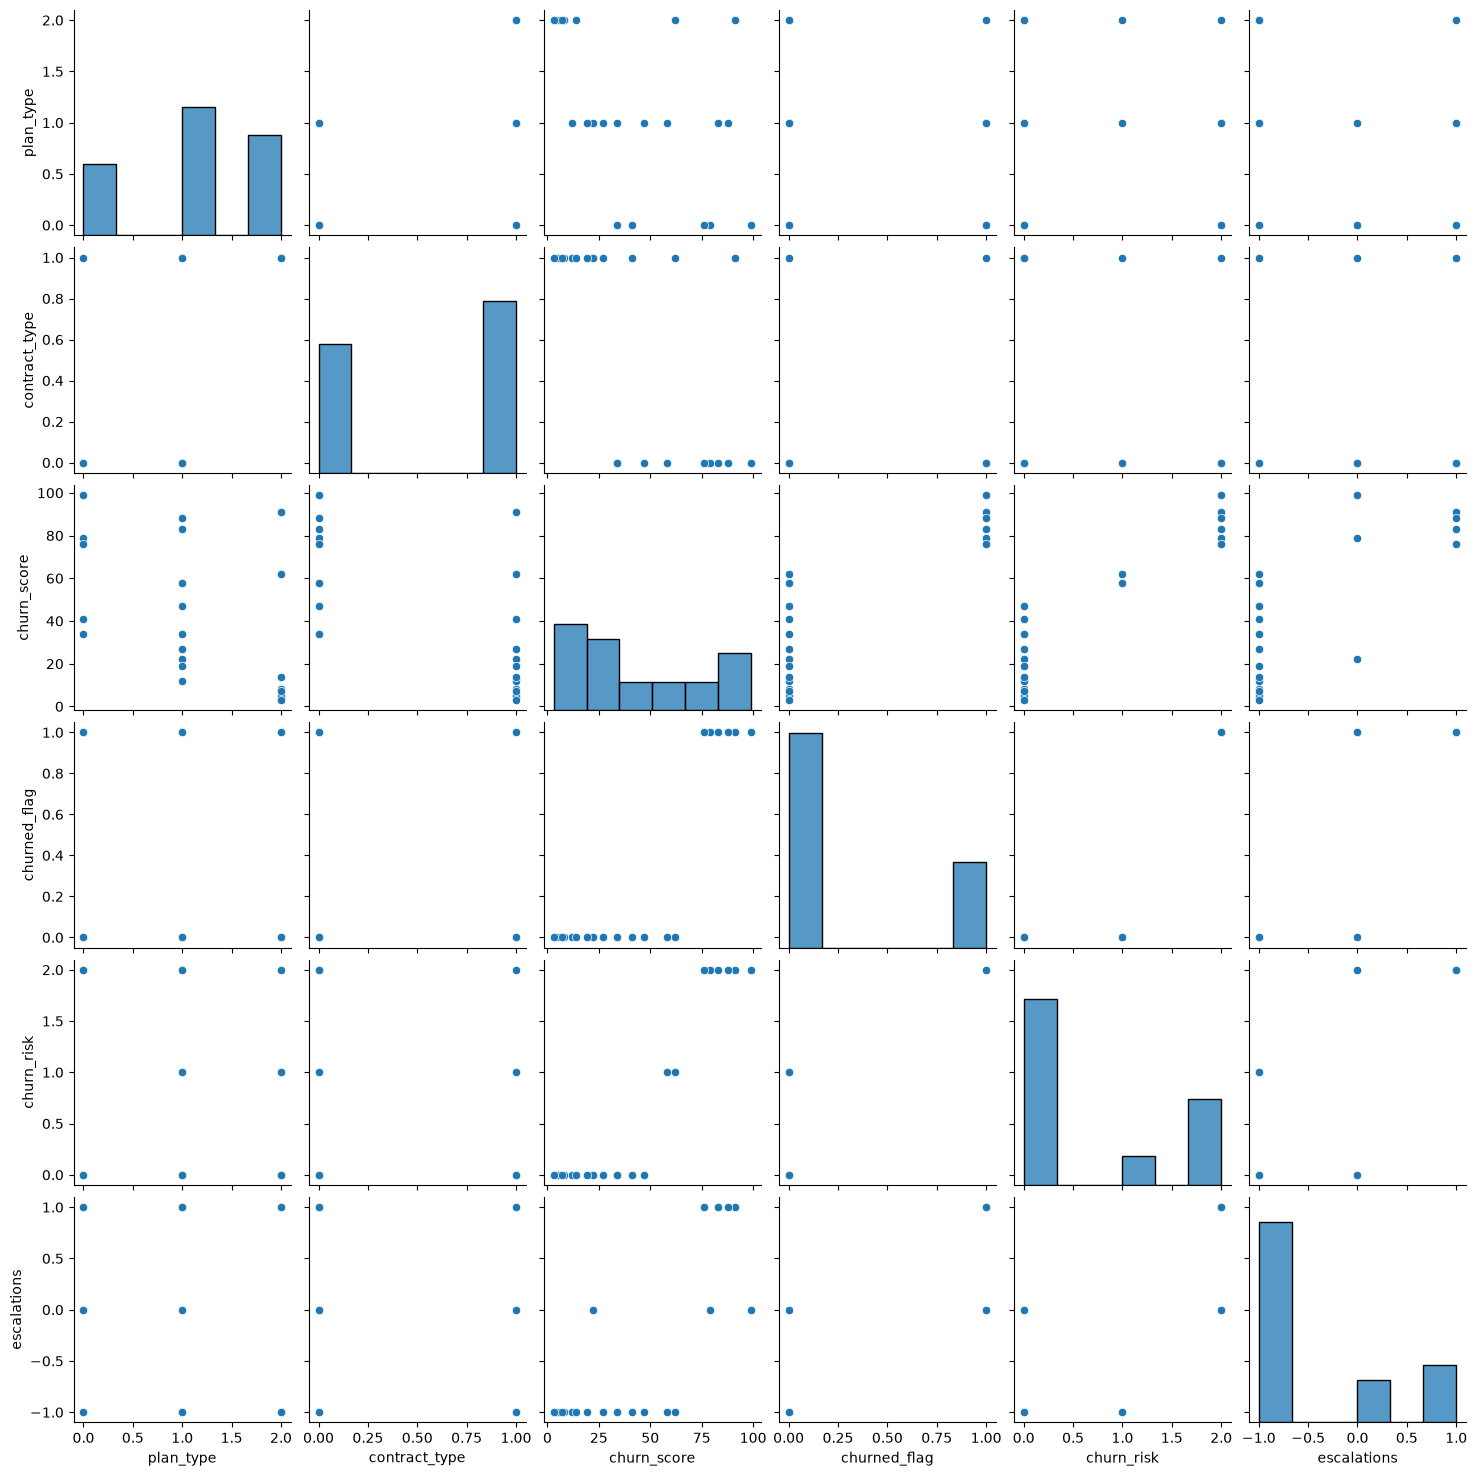

In [299]:
sns.pairplot(df_encoded)

In [316]:
#pivot table
pd.pivot_table(
    df_visual,
    values='monthly_charges',
    index='plan_type',
    aggfunc= 'mean', 
)

,monthly_charges
plan_type,
Basic,10.590000
Premium,31.275714
Standard,13.767778


In [315]:
pd.pivot_table(
    df_visual,
    index='plan_type',
    values=['monthly_charges', 'customerid', 'churned_flag'],
    aggfunc = {
        'monthly_charges' : 'sum',
        'customerid' : 'nunique',
        'churned_flag' : 'mean'
    }
)

,churned_flag,customerid,monthly_charges
plan_type,,,
Basic,0.600000,5,52.95
Premium,0.142857,7,218.93
Standard,0.222222,9,123.91


In [ ]:
#machine learning



In [ ]:
df['churned_flag']

In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score

# Select input features
x = df[['tenure_days', 'monthly_charges']].copy()

# Select target variable: 0 = Retained, 1 = Churned
y = df['churned_flag'].copy()

# Split data into 80% training and 20% testing
X_train, X_test, Y_train, Y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

# Print the number of training rows and features
print("Training data shape:", X_train.shape)

# Print the number of testing rows and features
print("Testing data shape:", X_test.shape)

# Create the Logistic Regression model
model = LogisticRegression()

# Train the model using training data
model.fit(X_train, Y_train)

# Predict probabilities for training and testing data
train_pred = model.predict_proba(X_train)
test_pred = model.predict_proba(X_test)

# Predict final classes: 0 = Retained, 1 = Churned
train_class_pred = model.predict(X_train)
test_class_pred = model.predict(X_test)

# Print predicted classes for training data
print("Training class predictions:", train_class_pred)

# Print predicted classes for testing data
print("Testing class predictions:", test_class_pred)

# Calculate the confusion matrix using test data
cm = confusion_matrix(Y_test, test_class_pred)

# Print the confusion matrix: [[TN, FP], [FN, TP]]
print("Test confusion matrix:")
print(cm)

# Calculate accuracy
test_accuracy = accuracy_score(Y_test, test_class_pred)

# Print the proportion of correct predictions
print("Test accuracy score:", test_accuracy)

# Calculate precision
test_precision = precision_score(Y_test, test_class_pred)

# Print how many predicted churners actually churned
print("Test precision score:", test_precision)

# Calculate recall
test_recall = recall_score(Y_test, test_class_pred)

# Print how many actual churners the model identified
print("Test recall score:", test_recall)